Dataset shape: (569, 30)
Classes: [0 1]
--- My Logistic Regression Results ---
              precision    recall  f1-score   support

           0       0.93      0.98      0.95        42
           1       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



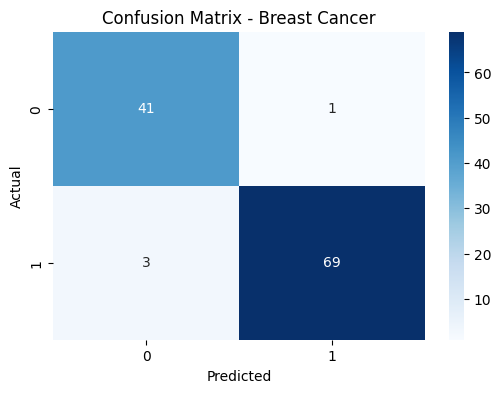

In [3]:
# My Machine Learning Assignment - Task A1
# Dataset: Breast Cancer Wisconsin

import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the data from sklearn
cancer_data = load_breast_cancer()
input_features = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
target_labels = cancer_data.target

# Quick check of the data
print("Dataset shape:", input_features.shape)
print("Classes:", np.unique(target_labels))

# 2. Split into train and test sets (80/20 split)
# I'm using stratify to keep the classes balanced
train_features, test_features, train_labels, test_labels = train_test_split(
    input_features, target_labels, test_size=0.2, random_state=7, stratify=target_labels
)

# 3. Set up the Pipeline
# I need to scale the data before putting it into Logistic Regression
my_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])

# 4. Train the model
my_pipeline.fit(train_features, train_labels)
predictions = my_pipeline.predict(test_features)

# 5. Print the evaluation metrics
print("--- My Logistic Regression Results ---")
print(classification_report(test_labels, predictions))

# 6. Create the Confusion Matrix plot
cm = confusion_matrix(test_labels, predictions)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Breast Cancer')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

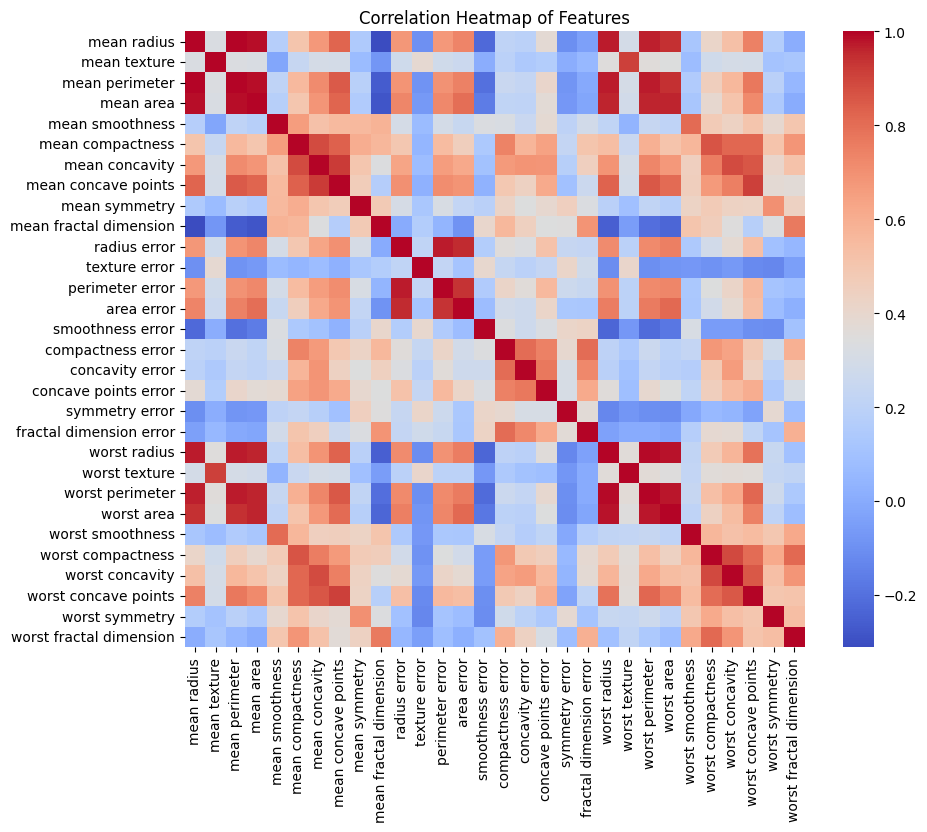

In [4]:
# Extra EDA as requested by the assignment
plt.figure(figsize=(10,8))
sns.heatmap(input_features.corr(), cmap='coolwarm', annot=False)
plt.title('Correlation Heatmap of Features')
plt.show()